In [3]:
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
import Minimal_Model_2D as mm2D
import time

In [4]:
#### first plotting wavefunction in real space for near zero spin orbit coupling 

NSM = 60           # number
M = 60             # Note: M*Ay should atleast be 3 times LY
AX = 5             # lattice spacing in nm
AY = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023    # proximitized InAs
MEFF_SM = 0.023    # InAs
NSC = 600
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_REF = 1E-5  #meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8          # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands


#### First find wavefunction of SNS with 0 spin orbit coupling

t1 = time.time()

print(t1)

Fcu_ref = mm2D.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT_REF, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
            
#Hcu = Fcu.H_sys(PHI, so = 'cu', uncorr_var=1, lmbda=1)
Hcu = Fcu_ref.H_sys(PHI, so = 'cu')
Ecu, V = eigsh(Hcu ,k=K_NUM ,sigma=0, return_eigenvectors=True)

# Get the indices that would sort Ecu
sorted_indices = np.argsort(Ecu)

# Sort Ecu using the sorted indices
sorted_Ecu = Ecu[sorted_indices]

# Sort the columns of V according to the sorted indices
sorted_V = V[:, sorted_indices]

print(sorted_Ecu, sorted_V.shape)

WV_ref = sorted_V[:, K_NUM//2]

# Save the array
np.save('GS_wv_SNS.npy', WV_ref)

print(np.sum(np.abs(WV_ref)**2))

t2 = time.time()

print(t2-t1)

1717700890.7408378
[-0.16698858 -0.16698858 -0.07559192 -0.07559192  0.07559192  0.07559192
  0.16698858  0.16698858] (302400, 8)
1.0000000000000022
388.77121663093567


In [12]:
pwd

'c:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_effect_on_spin_Splitting'

In [67]:
# Load the array
#WV_ref = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_effect_on_spin_Splitting\\GS_wv_SNS.npy")
WV_ref = np.load("GS_wv_SNS.npy")

In [15]:
WV_ref_reshaped = WV_ref.reshape((2,2,M,NTOT))

(60, 2) (60, 2) (60, 2)


In [57]:

XM, YM = np.meshgrid(X,Y)
Z = np.abs(WV_ref_reshaped[0,0,:,:])**2

print(XM.shape, YM.shape, Z.shape)


(60, 1260) (60, 1260) (60, 1260)


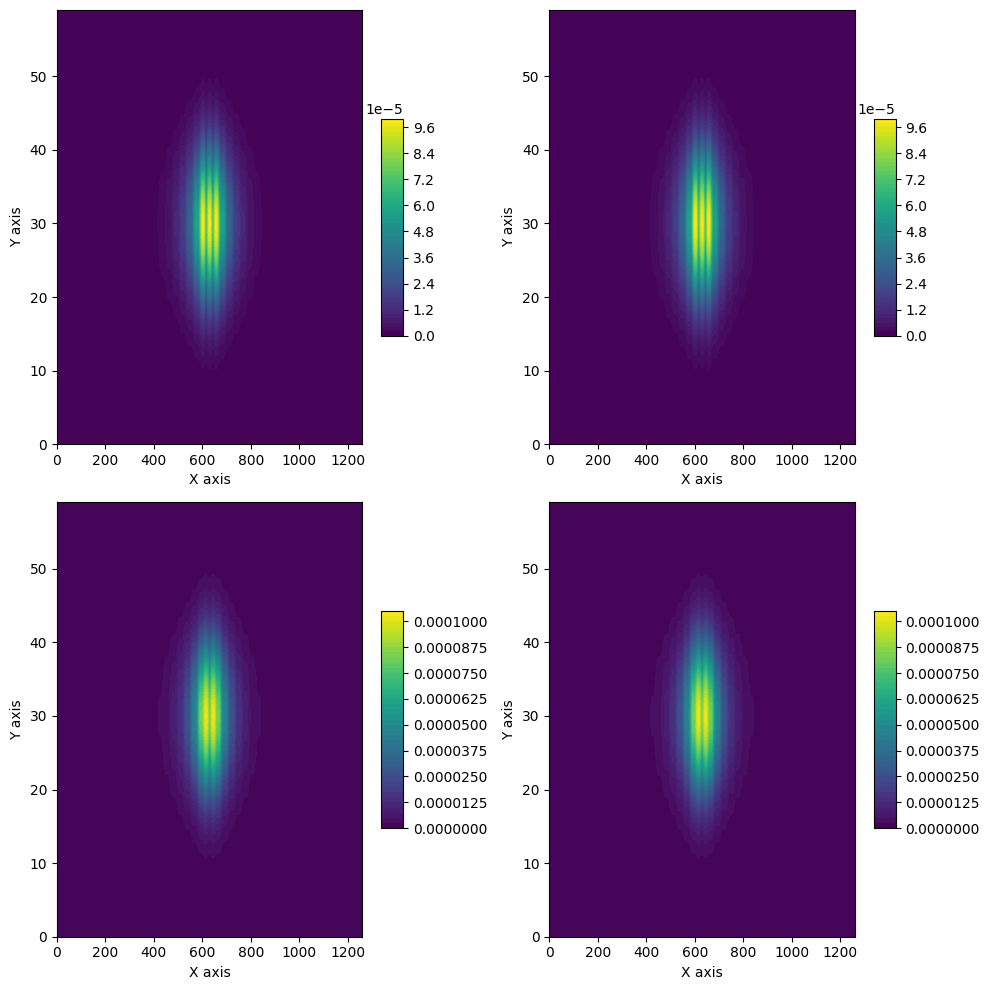

In [58]:


# Assuming XM and YM are meshgrids already created along with WV_ref_reshaped data
# You may need to redefine these or ensure they're available in your workspace

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Iterate over each subplot and plot the specific data
i = 0
for ax in np.nditer(axes, flags=['refs_ok']):
    # Get the current axis from the iterator
    ax = ax.item()

    # Select the appropriate slice of the WV_ref_reshaped data
    Z = np.abs(WV_ref_reshaped[i//2, i%2, :, :])**2

    # Generate contour plot for the selected data slice
    contourf = ax.contourf(XM, YM, Z, 50, cmap='viridis')  # Using 50 levels for the contour
    
    # Set titles and labels
    #ax.set_title(f'Contour Plot ')
    ax.set_xlabel('X axis')
    ax.set_ylabel('Y axis')

    # Add a color bar specific to each subplot
    fig.colorbar(contourf, ax=ax, shrink=0.5, aspect=10)

    # Increment the index for selecting data slices
    i += 1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()


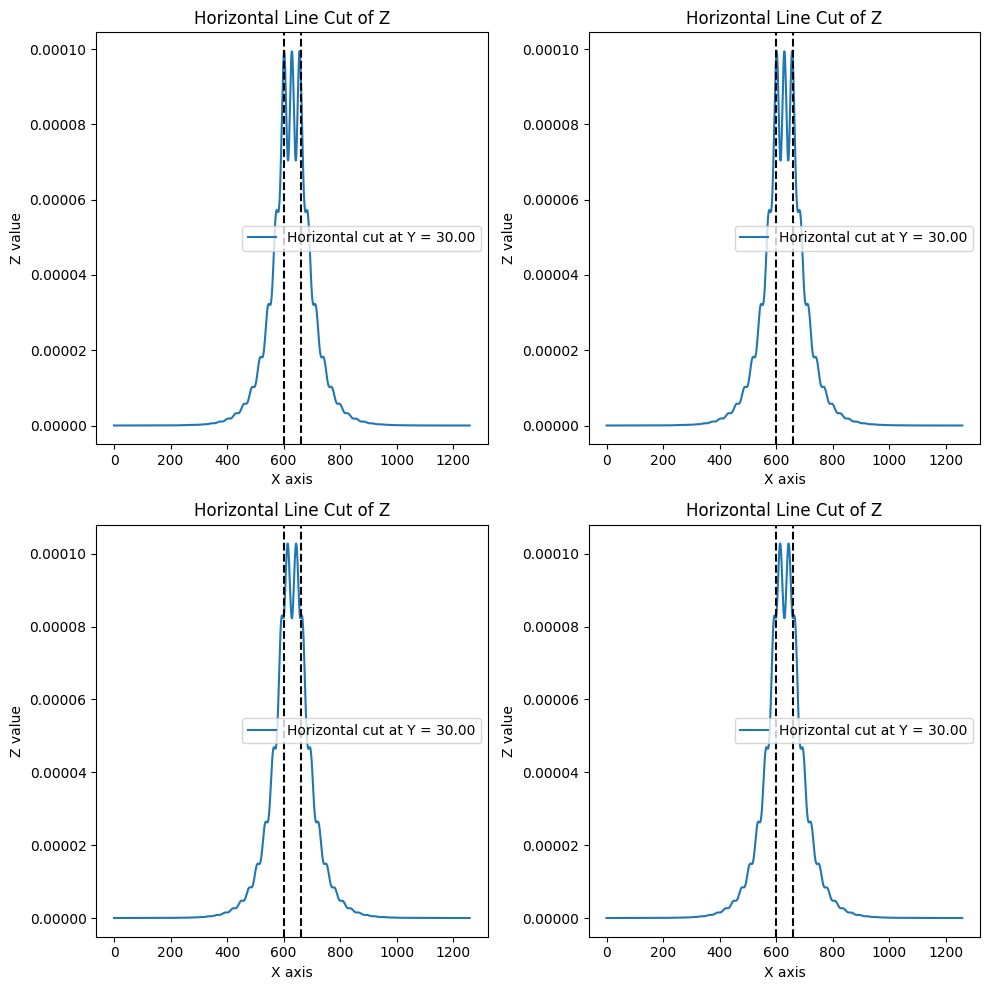

In [66]:
# Choose a specific index for the Y-axis
y_index = 30



# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Iterate over each subplot and plot the same data
i = 0 
for ax in axes.flatten():

    Z = np.abs(WV_ref_reshaped[i//2,i%2,:,:])**2
    # Extract the Z values at this Y index
    Z_line_cut = Z[y_index, :]
    ax.plot(XM[0, :], Z_line_cut, label=f'Horizontal cut at Y = {YM[ y_index,0]:.2f}')
    ax.axvline(x=NSC, color='black', linestyle='dashed')
    ax.axvline(x=NSC+NSM, color='black', linestyle='dashed')
    ax.legend()
    ax.set_xlabel('X axis')
    ax.set_ylabel('Z value')
    ax.set_title('Horizontal Line Cut of Z')

    i+=1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [61]:
WV_ref2 = sorted_V[:, K_NUM//2 + 1]

WV_ref2_reshaped = WV_ref2.reshape((2,2,M,NTOT))

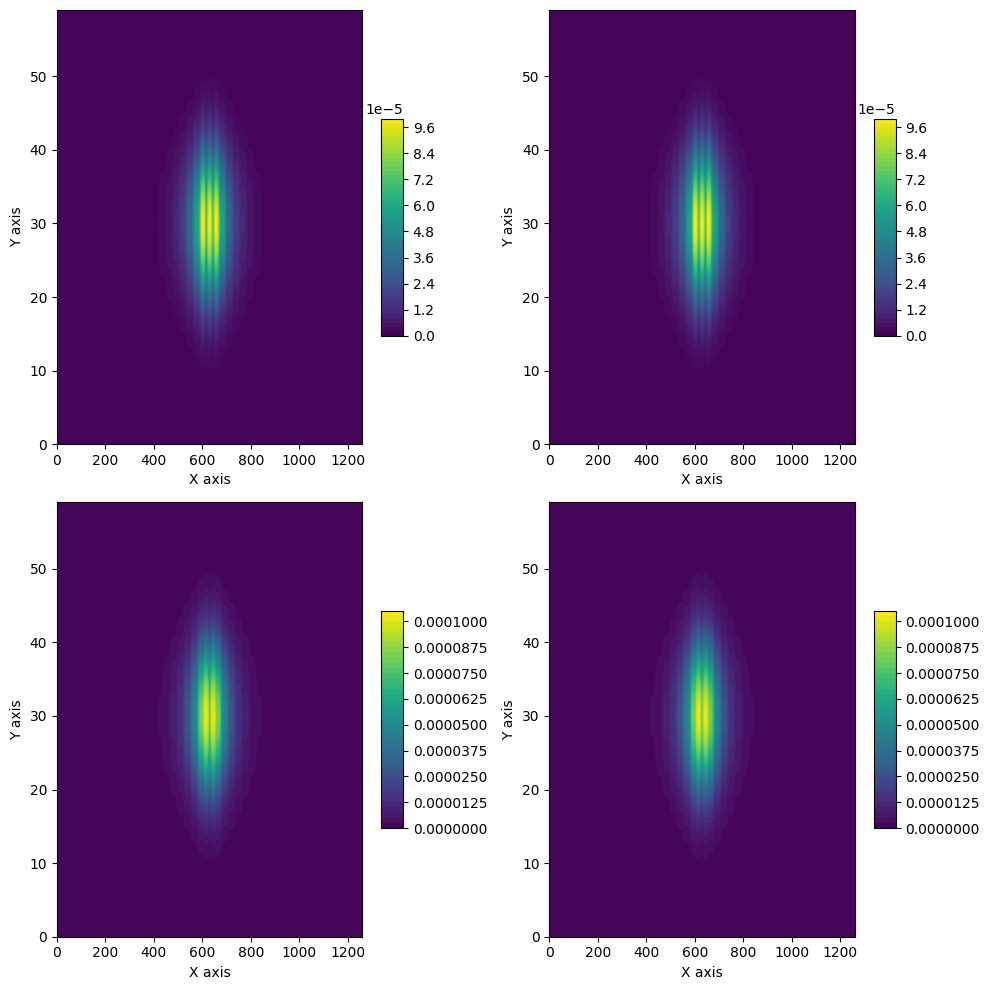

In [62]:


# Assuming XM and YM are meshgrids already created along with WV_ref_reshaped data
# You may need to redefine these or ensure they're available in your workspace

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Iterate over each subplot and plot the specific data
i = 0
for ax in np.nditer(axes, flags=['refs_ok']):
    # Get the current axis from the iterator
    ax = ax.item()

    # Select the appropriate slice of the WV_ref_reshaped data
    Z = np.abs(WV_ref2_reshaped[i//2, i%2, :, :])**2

    # Generate contour plot for the selected data slice
    contourf = ax.contourf(XM, YM, Z, 50, cmap='viridis')  # Using 50 levels for the contour
    
    # Set titles and labels
    #ax.set_title(f'Contour Plot ')
    ax.set_xlabel('X axis')
    ax.set_ylabel('Y axis')

    # Add a color bar specific to each subplot
    fig.colorbar(contourf, ax=ax, shrink=0.5, aspect=10)

    # Increment the index for selecting data slices
    i += 1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()


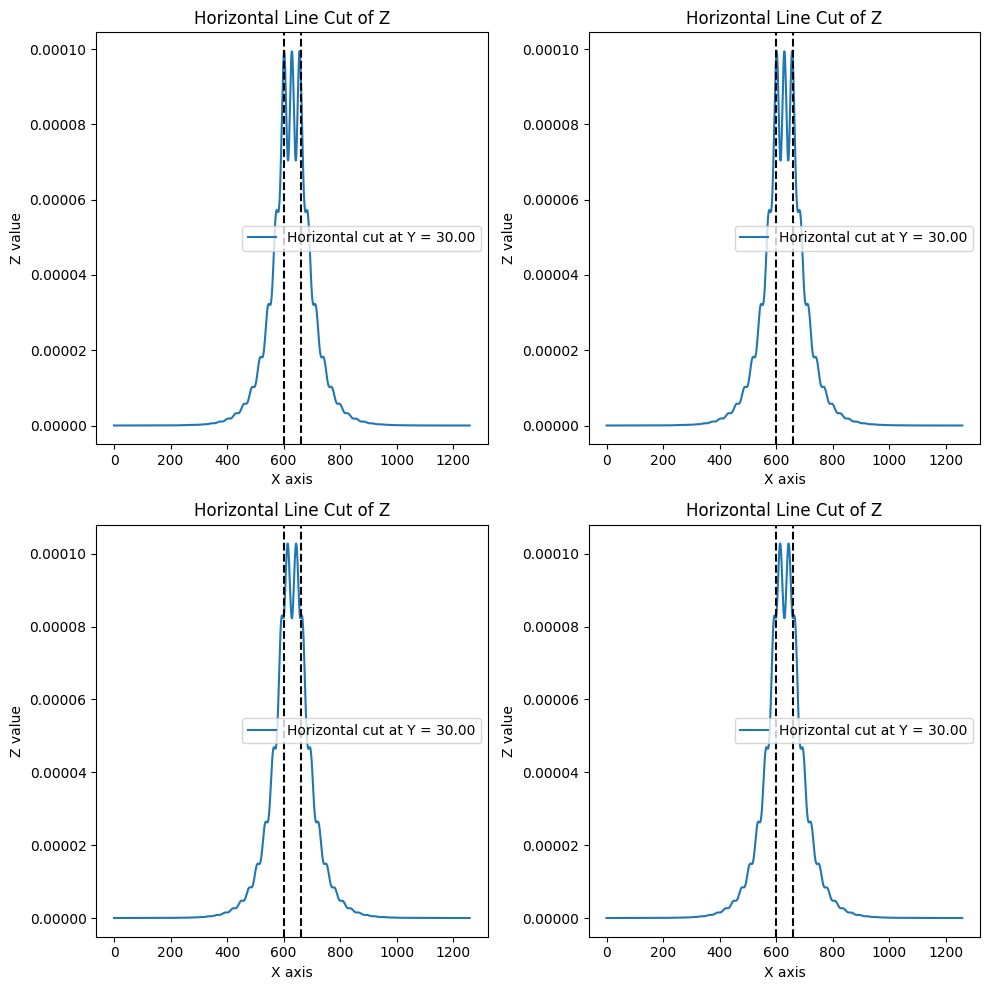

In [65]:
# Choose a specific index for the Y-axis
y_index = 30



# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Iterate over each subplot and plot the same data
i = 0 
for ax in axes.flatten():

    Z = np.abs(WV_ref2_reshaped[i//2,i%2,:,:])**2
    # Extract the Z values at this Y index
    Z_line_cut = Z[y_index, :]
    ax.plot(XM[0, :], Z_line_cut, label=f'Horizontal cut at Y = {YM[ y_index,0]:.2f}')
    ax.axvline(x=NSC, color='black', linestyle='dashed')
    ax.axvline(x=NSC+NSM, color='black', linestyle='dashed')
    ax.legend()
    ax.set_xlabel('X axis')
    ax.set_ylabel('Z value')
    ax.set_title('Horizontal Line Cut of Z')

    i+=1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()